# Day 1 lecture: Exploring data in Python

<p class="lead">
Before anyone trusts a number, an analyst explores the table it came from. This lecture teaches a repeatable exploration routine in pandas: check the structure and data quality, describe distributions and skew, summarise groups with pivot tables, measure relationships with correlation, look for hidden confounders, and draw charts that still work with tens of thousands of rows.
</p>

Open this notebook in JupyterLab from the course folder and run each cell from top to bottom with **Shift + Enter**.

---

## What you will be able to do

1. Inspect a new table's structure with `shape`, `info`, `dtypes` and `isnull`, and list its data-quality problems.
2. Describe a numeric column with the right summary, and recognise a **skewed** distribution.
3. Summarise one measure across two categories with `pd.pivot_table` and `groupby`.
4. Compute a **correlation matrix**, draw it as a **heatmap**, and read the strength and direction of each relationship.
5. Explain **confounding** and **Simpson's paradox**, and check a comparison by holding a third variable roughly constant.
6. Choose a **violin plot** or a **hexbin plot** when a box plot or scatter plot hides the shape of the data.

**Reading:** Qlik, *What is descriptive analytics?*; Analytics Vidhya (2015), *Ultimate guide for data exploration in Python*.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. **Check your understanding** boxes are short questions to answer in your own words, alone or with the person next to you.

| Part | Topic |
|---|---|
| 1 | The exploration routine |
| 2 | Structure and data quality |
| 3 | Distributions and skew |
| 4 | Pivot tables and groupby |
| 5 | Correlation and the heatmap |
| 6 | Confounding and Simpson's paradox |
| 7 | Charts for large datasets |

---

## Recap: this morning

Answer from memory, then check with the person next to you.

1. Which kind of analytics answers *"why did it happen?"*
2. Anscombe's four datasets share their means, spreads and correlation. What should you always do before trusting summary numbers?
3. A total can reverse the story told by every one of its parts. What is that trap called?

---

## Part 1: The exploration routine

**Exploratory data analysis (EDA)** is the first look at a new dataset: what is in it, whether it can be trusted, and which patterns are worth a closer look. It is **descriptive** and **diagnostic** analytics in practice. Analysts follow roughly the same routine every time:

| Step | Question | pandas and charts |
|---|---|---|
| **1. Structure** | How many rows and columns? What does one row mean? Which types? | `shape`, `info()`, `dtypes`, `head()` |
| **2. Data quality** | What is missing, duplicated or impossible? | `isnull().sum()`, `duplicated()`, `describe()` (min and max) |
| **3. Distributions** | What is typical? How spread out? Symmetric or skewed? | `describe()`, `skew()`, histogram, box or violin plot |
| **4. Groups** | How does a measure differ between categories? | `groupby`, `pd.pivot_table` |
| **5. Relationships** | Which numeric columns move together, and how strongly? | `corr()`, heatmap, scatter or hexbin plot |
| **6. Confounders** | Could a third variable explain the difference? | Compare within groups of that variable |

We use two tables you have in the `data` folder, so everything runs without internet:

| Table | One row is | Used for |
|---|---|---|
| `mpg.csv` | One car model from 1970–1982 (fuel economy in miles per gallon, engine and weight) | Structure, quality, correlation, confounding |
| `tips.csv` | One restaurant bill, with the tip (US dollars) | Distributions, pivot tables |

The lab applies the same routine to a third table.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

cars = pd.read_csv("data/mpg.csv")
tips = pd.read_csv("data/tips.csv")
tips["tip_percent"] = 100 * tips["tip"] / tips["total_bill"]

print("cars:", cars.shape, "| tips:", tips.shape)

cars: (398, 9) | tips: (244, 8)


---

## Part 2: Structure and data quality

### Structure

`shape` gives (rows, columns). `info()` lists every column with its **type** and its count of **non-null** (recorded) values. Compare that count with the number of rows: a lower number means missing values.

In [2]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


> **Predict, then reveal**
>
> Read the `Non-Null Count` column in the output above. Which column has fewer values than there are rows? Then run the next cell, which counts the missing values directly.

In [3]:
print("Missing values per column:")
print(cars.isnull().sum())

Missing values per column:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


`isnull()` marks each missing cell as `True`; `.sum()` counts the `True` values in each column. Let us look at the rows concerned rather than guess:

In [4]:
cars[cars["horsepower"].isnull()][["name", "model_year", "weight", "horsepower"]]

,name,model_year,weight,horsepower
32,ford pinto,71,2046,NaN
126,ford maverick,74,2875,NaN
330,renault lecar deluxe,80,1835,NaN
336,ford mustang cobra,80,2905,NaN
354,renault 18i,81,2320,NaN
374,amc concord dl,82,3035,NaN


A missing value is **not available**, not zero. Filling it with 0 would invent engines with no power and pull every average down. Common choices are:

| Choice | When it makes sense |
|---|---|
| **Keep and note** | Few rows are affected and pandas skips missing values in means and correlations anyway |
| **Drop the rows** for an analysis that needs the column | The rows are a small share and missing for no particular reason |
| **Fill in (impute)** with a typical value | Only with a stated reason, and never silently |

Here we keep the rows and note it: pandas ignores missing values when it computes a mean or a correlation.

### Other quality checks

Missing values are only one problem. Check for **duplicated rows** and **impossible values**. `describe()` shows each column's minimum and maximum, which is the fastest way to spot a weight of zero or a year of 2099.

In [5]:
print("Fully duplicated rows:", cars.duplicated().sum())
cars.describe().round(1)

Fully duplicated rows: 0


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.0,398.0,398.0,392.0,398.0,398.0,398.0
mean,23.5,5.5,193.4,104.5,2970.4,15.6,76.0
std,7.8,1.7,104.3,38.5,846.8,2.8,3.7
min,9.0,3.0,68.0,46.0,1613.0,8.0,70.0
25%,17.5,4.0,104.2,75.0,2223.8,13.8,73.0
50%,23.0,4.0,148.5,93.5,2803.5,15.5,76.0
75%,29.0,8.0,262.0,126.0,3608.0,17.2,79.0
max,46.6,8.0,455.0,230.0,5140.0,24.8,82.0


Read the `min` and `max` rows in the output above. Are they plausible for cars of that era (fuel economy, weight in pounds, model year as two digits)?

> **Data-quality checklist**
>
> 1. Row count and grain: what does one row mean?
> 2. Types: are numbers stored as numbers and categories as text?
> 3. Missing values: how many, where, and why?
> 4. Duplicates: genuine repeats or double entries?
> 5. Impossible values: zeros, negatives or extremes that cannot be true?
> 6. Write down what you found and what you did about it.

> **Check your understanding**
>
> A colleague replaces every missing `horsepower` with 0 and reports the average horsepower. What goes wrong? What would you do instead?

---

## Part 3: Distributions and skew

A **distribution** describes how the values of one column are spread out. Three questions describe it: what is **typical** (centre), how **spread out** it is, and what **shape** it has.

> **Predict, then reveal**
>
> Restaurant bills cannot be negative, and most are modest, but a few parties spend a lot. Will the **mean** bill be above, below or equal to the **median** bill? Write your guess, then run the next cell.

In [6]:
bill = tips["total_bill"]
print(f"Mean bill:   {bill.mean():.2f} US dollars")
print(f"Median bill: {bill.median():.2f} US dollars")
print(f"Skewness:    {bill.skew():.2f}")

Mean bill:   19.79 US dollars
Median bill: 17.80 US dollars
Skewness:    1.13


**Skewness** measures how lopsided a distribution is:

| Skewness | Shape | Mean compared with median | Typical business examples |
|---|---|---|---|
| Close to 0 | Roughly symmetric | About equal | Heights, measurement errors |
| Clearly positive (about 1 or more) | **Right-skewed**: a long tail of large values | Mean **above** the median | Bills, incomes, prices, order sizes |
| Clearly negative | **Left-skewed**: a long tail of small values | Mean **below** the median | Scores on an easy test |

With a right-skewed column, a few large values pull the mean up, so the **median** is the better "typical" value to report. The histogram shows the tail:

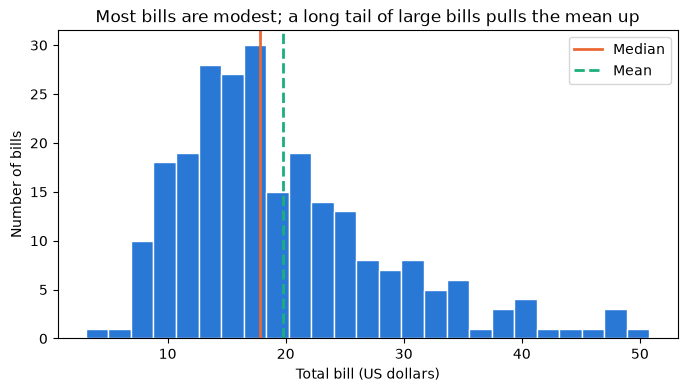

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(bill, bins=25, color="#2a78d6", edgecolor="white")
ax.axvline(bill.median(), color="#eb6834", linewidth=2, label="Median")
ax.axvline(bill.mean(), color="#1baf7a", linewidth=2, linestyle="--", label="Mean")
ax.set_title("Most bills are modest; a long tail of large bills pulls the mean up")
ax.set_xlabel("Total bill (US dollars)")
ax.set_ylabel("Number of bills")
ax.legend()
plt.show()

### Comparing distributions across groups: the violin plot

A **box plot** summarises each group with five numbers. A **violin plot** draws the whole shape: the width at each height shows how many values lie there, like a histogram turned on its side and mirrored. The thin box inside marks the middle half and the median. `cut=0` stops each violin at the smallest and largest real value, so it never suggests a negative bill. Violins are useful when a group has two peaks or a long tail, which a box plot hides.

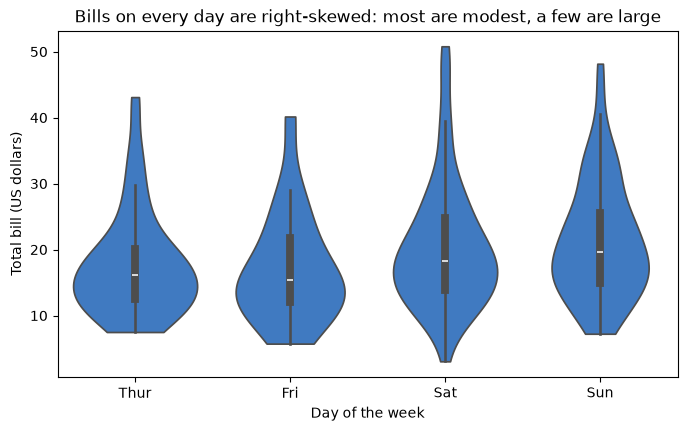

In [8]:
day_order = ["Thur", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=tips, x="day", y="total_bill", order=day_order, color="#2a78d6", cut=0, ax=ax)
ax.set_title("Bills on every day are right-skewed: most are modest, a few are large")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Total bill (US dollars)")
plt.show()

Each violin is wide near the bottom (many modest bills) and has a thin neck reaching upwards (a few large bills): the right-skewed shape again, on every day.

> **Check your understanding**
>
> A manager reads that the average house price in a city is far above what most families paid. Using the words *skew*, *mean* and *median*, explain how both statements can be true. Which number should the report lead with?

---

## Part 4: Pivot tables and groupby

Business questions often compare a measure across **two** categories at once: tip percentage by **day** and by **time** (lunch or dinner), sales by region and by product, price by quality and by grade. A **pivot table** puts one category in the rows, another in the columns, and a summary of the measure in each cell. It is the same idea as a pivot table in Excel.

`pd.pivot_table` needs four things:

| Argument | Meaning | Here |
|---|---|---|
| `values` | The measure to summarise | `tip_percent` |
| `index` | The category for the rows | `day` |
| `columns` | The category for the columns | `time` |
| `aggfunc` | The summary for each cell | `"mean"` |

In [9]:
tip_pivot = pd.pivot_table(
    data=tips,
    values="tip_percent",
    index="day",
    columns="time",
    aggfunc="mean",
).reindex(day_order)

print("Average tip (% of the bill) by day and time")
tip_pivot.round(1)

Average tip (% of the bill) by day and time


time,Dinner,Lunch
day,,
Thur,16.0,16.1
Fri,15.9,18.9
Sat,15.3,NaN
Sun,16.7,NaN


`.reindex(day_order)` puts the rows in calendar order instead of alphabetical order.

> **Predict, then reveal**
>
> Some cells in the output above show `NaN`. Is that a tip percentage of zero? Before reading on, guess what it means.

`NaN` means **not available**: there were no bills in that combination (the restaurant served no weekend lunches in this data). An empty cell is not a zero.

A pivot table of averages should always be read next to the **counts** behind each cell, because an average of three bills is far less reliable than an average of eighty:

In [10]:
count_pivot = pd.pivot_table(
    data=tips, values="tip_percent", index="day", columns="time", aggfunc="count",
).reindex(day_order)

print("Number of bills behind each average")
count_pivot

Number of bills behind each average


time,Dinner,Lunch
day,,
Thur,1.0,61.0
Fri,12.0,7.0
Sat,87.0,NaN
Sun,76.0,NaN


### The same summary with groupby

`groupby` with two columns gives the same numbers in a long table: one row per combination. Use whichever is easier to read. `observed=True` keeps only combinations that actually occur.

In [11]:
tips.groupby(["day", "time"], observed=True).agg(
    bills=("tip_percent", "count"),
    average_tip_percent=("tip_percent", "mean"),
).round(1)

bills  average_tip_percent
day  time                              
Fri  Dinner     12                 15.9
     Lunch       7                 18.9
Sat  Dinner     87                 15.3
Sun  Dinner     76                 16.7
Thur Dinner      1                 16.0
     Lunch      61                 16.1

> **Check your understanding**
>
> Write the `pd.pivot_table` call that shows the **median** total bill with `sex` in the rows and `smoker` in the columns. Which argument changes, and why might the median suit bills better than the mean?

---

## Part 5: Correlation and the heatmap

The **correlation coefficient** *r* measures how closely two numeric columns follow a **straight line**:

| *r* | Reading |
|---|---|
| +1 | Perfect straight line going up |
| about +0.7 or more | Strong positive relationship |
| about 0 | No straight-line relationship (there may still be a curve) |
| about −0.7 or less | Strong negative relationship |
| −1 | Perfect straight line going down |

`corr()` computes *r* for every pair of numeric columns at once: a **correlation matrix**. `select_dtypes(include="number")` keeps only the numeric columns, because a correlation needs numbers.

In [12]:
numeric_cars = cars.select_dtypes(include="number")
corr_matrix = numeric_cars.corr()
corr_matrix.round(2)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
mpg,1.00,-0.78,-0.80,-0.78,-0.83,0.42,0.58
cylinders,-0.78,1.00,0.95,0.84,0.90,-0.51,-0.35
displacement,-0.80,0.95,1.00,0.90,0.93,-0.54,-0.37
horsepower,-0.78,0.84,0.90,1.00,0.86,-0.69,-0.42
weight,-0.83,0.90,0.93,0.86,1.00,-0.42,-0.31
acceleration,0.42,-0.51,-0.54,-0.69,-0.42,1.00,0.29
model_year,0.58,-0.35,-0.37,-0.42,-0.31,0.29,1.00


A table of 49 numbers is hard to scan. A **heatmap** colours each cell by its value, with a diverging colour scale fixed from −1 to +1 so that colour means the same thing in every heatmap: one colour for positive, another for negative, pale near zero. `annot=True` prints the value in each cell.

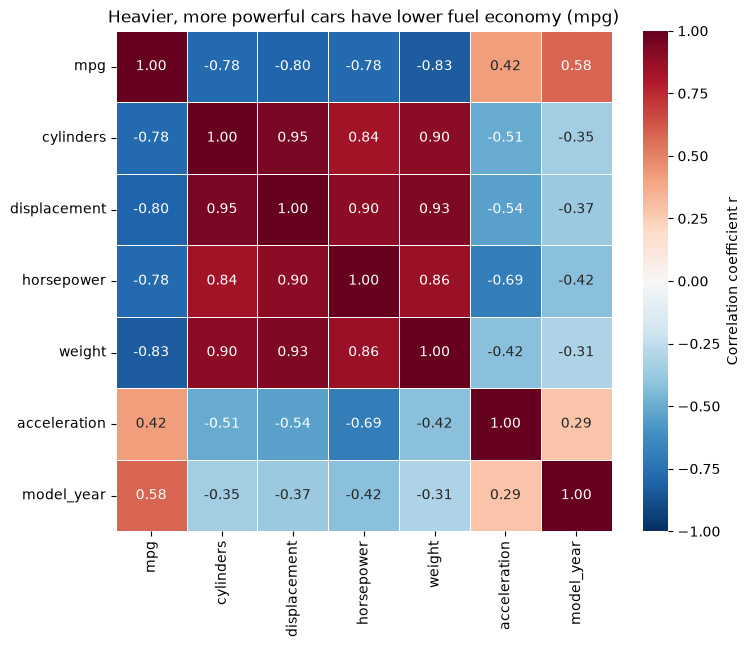

In [13]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r",
    vmin=-1, vmax=1, linewidths=0.5, ax=ax,
    cbar_kws={"label": "Correlation coefficient r"},
)
ax.set_title("Heavier, more powerful cars have lower fuel economy (mpg)")
plt.show()

Read the `mpg` row of the heatmap above: which column has the strongest relationship with fuel economy, and in which direction? Notice also the dark block of engine columns (`cylinders`, `displacement`, `horsepower`, `weight`) that are strongly correlated **with each other**: they largely measure the same thing, the size of the car.

> **Three warnings about correlation**
>
> 1. **Straight lines only.** A strong curve can have *r* near 0 (remember Anscombe's set II). Plot before you conclude.
> 2. **Association is not causation.** Two columns can move together because a third drives both.
> 3. **The diagonal is always 1.** Every column correlates perfectly with itself; ignore it.

> **Check your understanding**
>
> The correlation between `model_year` and `mpg` is positive. Does that prove that newer car designs *caused* better fuel economy? Name one other column that could be part of the explanation.

---

## Part 6: Confounding and Simpson's paradox

### A comparison that misleads

A **confounder** is a third variable that is related to both things you compare, and so distorts the comparison. Let us compare fuel economy of cars from the three regions of origin in the data.

In [14]:
cars.groupby("origin").agg(
    cars=("mpg", "count"),
    average_mpg=("mpg", "mean"),
    average_weight_lb=("weight", "mean"),
).round(1)

,cars,average_mpg,average_weight_lb
origin,,,
europe,70,27.9,2423.3
japan,79,30.5,2221.2
usa,249,20.1,3361.9


> **Predict, then reveal**
>
> The output above shows a large gap in average fuel economy between regions. Look also at the **weight** column. Is the gap mostly about where the car was built, or about something else? Write your answer, then run the next cell.

To check, we hold the suspected confounder roughly **constant**: cut weight into bands with `pd.cut`, then compare regions **within** each band.

In [15]:
cars["weight_band"] = pd.cut(
    cars["weight"],
    bins=[0, 2500, 3000, 3500, 6000],
    labels=["under 2,500 lb", "2,500-3,000 lb", "3,000-3,500 lb", "over 3,500 lb"],
)

within_band = pd.pivot_table(
    data=cars, values="mpg", index="origin", columns="weight_band",
    aggfunc="mean", observed=True,
)
print("Average mpg by origin, within weight bands (NaN = no cars of that origin and weight)")
within_band.round(1)

Average mpg by origin, within weight bands (NaN = no cars of that origin and weight)


weight_band,"under 2,500 lb","2,500-3,000 lb","3,000-3,500 lb","over 3,500 lb"
origin,,,,
europe,30.7,22.8,23.5,21.0
japan,31.7,26.0,NaN,NaN
usa,29.0,24.3,19.4,15.1


Compare the overall gap from the previous output with the gap **inside** each weight band above. Within a band, cars of similar weight from different regions are much closer than the overall averages suggested. A large part of the overall gap comes from the **mix**: one region's cars are mostly heavy, the others' mostly light. Weight is a **confounder**: it is related to origin and it drives fuel economy.

The chart shows the mix directly:

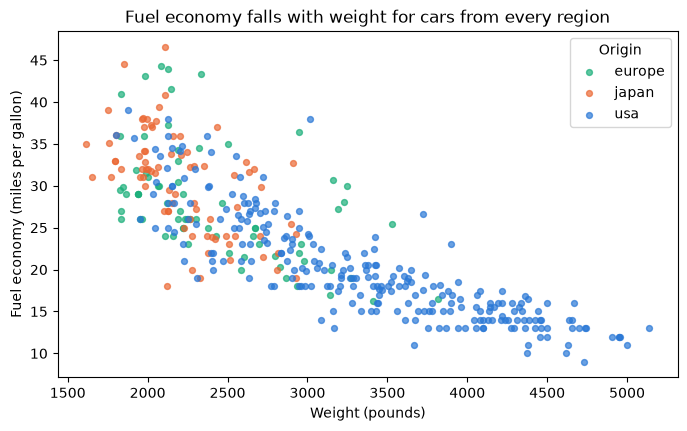

In [16]:
origin_colours = {"europe": "#1baf7a", "japan": "#eb6834", "usa": "#2a78d6"}

fig, ax = plt.subplots(figsize=(8, 4.5))
for origin, group in cars.groupby("origin"):
    ax.scatter(group["weight"], group["mpg"], s=18, alpha=0.7,
               color=origin_colours[origin], label=origin)
ax.set_title("Fuel economy falls with weight for cars from every region")
ax.set_xlabel("Weight (pounds)")
ax.set_ylabel("Fuel economy (miles per gallon)")
ax.legend(title="Origin")
plt.show()

### Simpson's paradox: when the total reverses every part

Sometimes a confounder does not just shrink a gap; it **reverses** it. A well-known medical study (Charig and colleagues, 1986) compared two treatments for kidney stones. The counts below are from that study.

In [17]:
stones = pd.DataFrame({
    "treatment":  ["A", "A", "B", "B"],
    "stone_size": ["small", "large", "small", "large"],
    "patients":   [87, 263, 270, 80],
    "successes":  [81, 192, 234, 55],
})

by_size = stones.assign(success_rate=100 * stones["successes"] / stones["patients"])
print("Success rate (%) within each stone size")
print(by_size.pivot_table(values="success_rate", index="treatment", columns="stone_size").round(1))

overall = stones.groupby("treatment")[["patients", "successes"]].sum()
overall["success_rate"] = 100 * overall["successes"] / overall["patients"]
print()
print("Success rate (%) overall")
print(overall.round(1))

Success rate (%) within each stone size
stone_size  large  small
treatment               
A            73.0   93.1
B            68.8   86.7

Success rate (%) overall
           patients  successes  success_rate
treatment                                   
A               350        273          78.0
B               350        289          82.6


> **Predict, then reveal**
>
> Before reading on: in the output above, which treatment wins for **small** stones? For **large** stones? And **overall**?

Treatment A has the higher success rate for small stones **and** for large stones, yet B looks better overall. The reason is the mix: doctors gave A mostly to **large**, difficult stones and B mostly to small, easy ones. Stone size affects both the treatment chosen and the chance of success, so it is a confounder, and adding the groups together reverses the story. This reversal is **Simpson's paradox**.

> **How to protect yourself**
>
> When a comparison between groups surprises you, ask: *what else differs between these groups?* Then compare **within** levels of that variable (bands, as above), or compare a **ratio** that removes it (for example fuel used per pound, or price per unit of size). You will meet a confounder in the lab.

> **Check your understanding**
>
> A hospital's overall death rate is higher than a nearby clinic's. Name a likely confounder, and say how you would check whether the hospital is really worse.

---

## Part 7: Charts for large datasets

With a few hundred rows a scatter plot works well. With tens of thousands, the dots pile on top of each other (**overplotting**): a solid blob hides where most of the data actually is.

To show this, the next cell creates **synthetic** (made-up) data for 50,000 deliveries: the distance in kilometres and the delivery time in minutes. The random generator is seeded, so everyone gets the same numbers.

In [18]:
rng = np.random.default_rng(300)
n = 50_000
distance_km = rng.gamma(shape=2.0, scale=3.0, size=n)
delivery_min = 10 + 4 * distance_km + rng.gamma(shape=2.0, scale=5.0, size=n)
deliveries = pd.DataFrame({"distance_km": distance_km, "delivery_min": delivery_min})

print("Synthetic deliveries:", deliveries.shape)
deliveries.describe().round(1)

Synthetic deliveries: (50000, 2)


,distance_km,delivery_min
count,50000.0,50000.0
mean,6.0,44.0
std,4.2,18.3
min,0.0,10.8
25%,2.9,30.6
50%,5.0,40.6
75%,8.1,53.7
max,39.7,179.0


> **Predict, then reveal**
>
> In a plain scatter plot of 50,000 deliveries, will you be able to see where **most** deliveries lie? Run the next cell and compare the two panels.

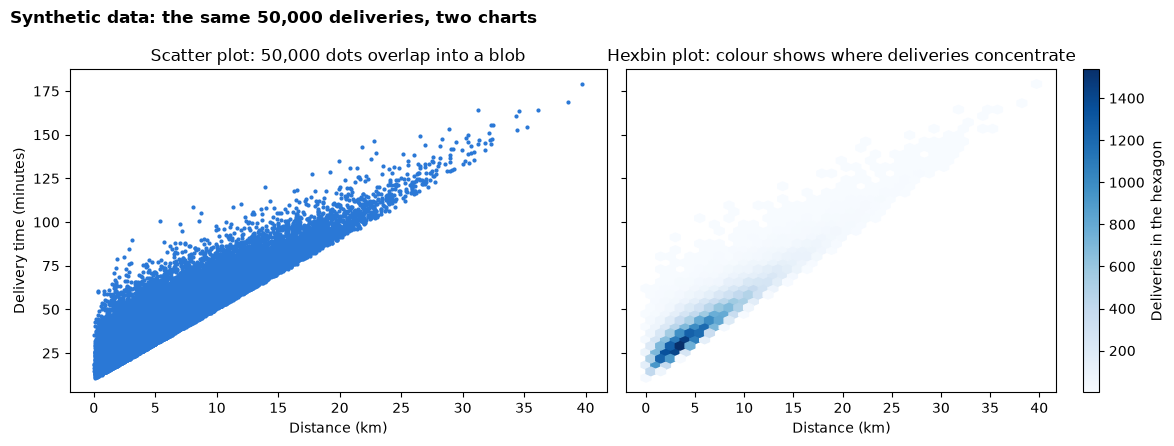

In [19]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)

left.scatter(deliveries["distance_km"], deliveries["delivery_min"], s=4, color="#2a78d6")
left.set_title("Scatter plot: 50,000 dots overlap into a blob")

hb = right.hexbin(deliveries["distance_km"], deliveries["delivery_min"],
                  gridsize=40, cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=right, label="Deliveries in the hexagon")
right.set_title("Hexbin plot: colour shows where deliveries concentrate")

for ax in (left, right):
    ax.set_xlabel("Distance (km)")
left.set_ylabel("Delivery time (minutes)")
fig.suptitle("Synthetic data: the same 50,000 deliveries, two charts", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

A **hexbin plot** divides the chart into hexagons and colours each one by how many points fall inside it, like a two-dimensional histogram. The darkest hexagons show where the data is **densest**: here, short deliveries of modest duration. `gridsize` sets how many hexagons fit across; `mincnt=1` leaves empty hexagons blank.

| Chart | Best for | Weakness |
|---|---|---|
| Scatter plot | Up to a few thousand rows; individual outliers | Overplotting with many rows |
| Hexbin plot | Two numeric columns with many rows | Hides individual points |
| Box plot | Comparing centre and spread across groups | Hides the shape (two peaks, gaps) |
| Violin plot | Comparing the full shape across groups | Harder for a non-technical audience to read |

> **Check your understanding**
>
> In the hexbin plot, where is the densest region, roughly (a distance range and a time range)? How would you describe it to an operations manager in one sentence?

---

## Summary

- Explore before you analyse: **structure → quality → distributions → groups → relationships → confounders**.
- `info()` and `isnull().sum()` find missing values; a missing value is **not available**, never zero. Check duplicates and impossible values with `duplicated()` and the min and max in `describe()`.
- Prices, bills and incomes are usually **right-skewed**: the mean sits above the median, so report the median as the typical value.
- `pd.pivot_table(values=, index=, columns=, aggfunc=)` compares a measure across two categories; always read the counts behind each average.
- `corr()` and a heatmap show straight-line relationships from −1 to +1; correlation is not causation.
- A **confounder** can shrink, inflate or reverse a comparison (**Simpson's paradox**). Compare within bands of the suspected confounder.
- With many rows, use a **hexbin** plot instead of a scatter plot, and a **violin** plot to see the full shape of each group.

## Quick reference

| You want to… | Code |
|---|---|
| Columns, types and non-null counts | `df.info()` |
| Missing values per column | `df.isnull().sum()` |
| Duplicated rows | `df.duplicated().sum()` |
| Skewness of a column | `df["col"].skew()` |
| Pivot table | `pd.pivot_table(data=df, values="y", index="a", columns="b", aggfunc="mean")` |
| Correlation matrix | `df.select_dtypes(include="number").corr()` |
| Heatmap | `sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)` |
| Bands of a number | `pd.cut(df["col"], bins=[...])` |
| Violin plot | `sns.violinplot(data=df, x="group", y="value")` |
| Hexbin plot | `plt.hexbin(df["x"], df["y"], gridsize=40, cmap="Blues", mincnt=1)` |

---

## Quiz: ready for the lab?

1. Which two pandas calls tell you whether a table has missing values, and how?
2. A column of prices has a mean of 4,000 and a median of 2,400. What shape is its distribution, and which number would you report as the typical price?
3. Write the `pd.pivot_table` call that shows the average `price` with `cut` in the rows and `color` in the columns of a table called `diamonds`.
4. In a correlation heatmap, one column has *r* = 0.92 with price and another *r* = −0.01. Describe each relationship in words.
5. A cheaper product grade sells for a higher average price than a better grade. Suggest one reason based on confounding, and one way to check it.
6. Why would you draw a hexbin plot instead of a scatter plot for 50,000 rows, and what does the darkest hexagon tell you?

---

## In the lab

[Applied Lab 1: Data exploration](D1_lab_lab1_diamonds.md) (3%) applies this routine to more than 50,000 diamonds for a jewellery retailer: structural inspection, a pivot table of price, a correlation heatmap, a violin plot and a hexbin plot, then six questions in your own words.